In [2]:
import math

initial_a = 1.5
initial_b = 1.0

raw_kc = input("Enter Kc: ")
print("Raw input type:", type(raw_kc))

try:
    kc = float(raw_kc)
except ValueError:
    print("Error: Kc must be a number.")
else:
    print("Converted value type:", type(kc))

    if not math.isfinite(kc):
        print("Error: Kc must be a finite number.")
    elif kc < 0:
        print("Error: Kc cannot be negative.")
    else:
        # Kc*x^2 - (2.5*Kc + 1)*x + 1.5*Kc = 0
        coeff_a = kc
        coeff_b = -(2.5 * kc + 1)
        coeff_c = 1.5 * kc
        discriminant = coeff_b**2 - 4 * coeff_a * coeff_c

        print(f"\nQuadratic coefficients: a={coeff_a}, b={coeff_b}, c={coeff_c}")
        print(f"Discriminant: {discriminant:.6f}")

        if kc == 0:
            # The equation becomes -x = 0, so it is linear, not quadratic.
            print("Quadratic roots: undefined because a = 0.")
            print("Linear solution: x = 0.000")
            x = 0.0
        else:
            sqrt_discriminant = math.sqrt(discriminant)
            root1 = (-coeff_b + sqrt_discriminant) / (2 * coeff_a)
            root2 = (-coeff_b - sqrt_discriminant) / (2 * coeff_a)

            print(f"Root 1: {root1:.6f}")
            print(f"Root 2: {root2:.6f}")

            meaningful_roots = [
                root for root in (root1, root2) if 0 < root < initial_b
            ]

            if not meaningful_roots:
                print("Error: No physically meaningful root found.")
                x = None
            else:
                x = meaningful_roots[0]

        if x is not None:
            equilibrium_a = initial_a - x
            equilibrium_b = initial_b - x
            equilibrium_c = x
            conversion = (x / initial_b) * 100

            print("\nEquilibrium concentrations:")
            print(f"[A] = {equilibrium_a:.3f} mol/L")
            print(f"[B] = {equilibrium_b:.3f} mol/L")
            print(f"[C] = {equilibrium_c:.3f} mol/L")
            print(f"B conversion = {conversion:.3f}%")

            if conversion > 70:
                classification = "high"
            elif conversion > 40:
                classification = "moderate"
            else:
                classification = "low"

            print("Conversion classification:", classification)

Raw input type: <class 'str'>
Converted value type: <class 'float'>

Quadratic coefficients: a=12.0, b=-31.0, c=18.0
Discriminant: 97.000000
Root 1: 1.702036
Root 2: 0.881298

Equilibrium concentrations:
[A] = 0.619 mol/L
[B] = 0.119 mol/L
[C] = 0.881 mol/L
B conversion = 88.130%
Conversion classification: high


In [3]:
#PART A

import math

initial_concentration = 2.5  # mol/L
k = 0.04                     # min^-1
dt = 1                       # min

# 1. Euler simulation for 12 minutes
time = 0
concentration = initial_concentration

print("Time (min)\tConcentration (mol/L)\tConversion (%)")
print(f"{time}\t\t{concentration:.4f}\t\t\t0.00")

for step in range(12):
    concentration = concentration - k * concentration * dt
    time += dt
    conversion = (initial_concentration - concentration) / initial_concentration * 100
    print(f"{time}\t\t{concentration:.4f}\t\t\t{conversion:.2f}")

# 2. Exact concentration and absolute error at 12 minutes
exact_concentration = initial_concentration * math.exp(-k * time)
absolute_error = abs(exact_concentration - concentration)

print(f"\nEuler concentration at {time} min: {concentration:.6f} mol/L")
print(f"Exact concentration at {time} min: {exact_concentration:.6f} mol/L")
print(f"Absolute error: {absolute_error:.6f} mol/L")

# 3. Euler simulation until conversion reaches 40% or time reaches 100 min
time = 0
concentration = initial_concentration
conversion = 0

while conversion < 40 and time < 100:
    concentration = concentration - k * concentration * dt
    time += dt
    conversion = (initial_concentration - concentration) / initial_concentration * 100

print(f"\nTime to reach 40% conversion (or 100 min): {time} min")
print(f"Final concentration: {concentration:.4f} mol/L")
print(f"Final conversion: {conversion:.2f}%")

Time (min)	Concentration (mol/L)	Conversion (%)
0		2.5000			0.00
1		2.4000			4.00
2		2.3040			7.84
3		2.2118			11.53
4		2.1234			15.07
5		2.0384			18.46
6		1.9569			21.72
7		1.8786			24.86
8		1.8035			27.86
9		1.7313			30.75
10		1.6621			33.52
11		1.5956			36.18
12		1.5318			38.73

Euler concentration at 12 min: 1.531774 mol/L
Exact concentration at 12 min: 1.546958 mol/L
Absolute error: 0.015184 mol/L

Time to reach 40% conversion (or 100 min): 13 min
Final concentration: 1.4705 mol/L
Final conversion: 41.18%


In [8]:
#PART B
code = input("Enter the sample code: ")

if code == "":
    print("The code is empty.")
else:
    digit_count = 0
    digit_sum = 0

    for character in code:
        if character.isdecimal():
            digit = int(character)
            digit_count += 1
            digit_sum += digit

    if digit_count == 0:
        print("The code contains no digits.")
    else:
        print("Number of digits:", digit_count)
        print("Sum of digits:", digit_sum)

Number of digits: 4
Sum of digits: 10


In [10]:
def factorial(n):
    if n < 0:
        raise ValueError("n must be non-negative.")
    if n == 0:
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if n < 0 or r < 0:
        raise ValueError("n and r must be non-negative.")
    if r > n:
        raise ValueError("r cannot be greater than n.")

    return factorial(n) // (factorial(r) * factorial(n - r))


print("Number of mixtures for n=9, r=3:", combination(9, 3))

try:
    print("Number of mixtures for n=6, r=8:", combination(6, 8))
except ValueError as error:
    print("Invalid input:", error)

Number of mixtures for n=9, r=3: 84
Invalid input: r cannot be greater than n.


In [11]:
def fib_iter(n):
    numbers = []
    a, b = 0, 1

    for _ in range(n):
        numbers.append(a)
        a, b = b, a + b

    return numbers


def fib_rec(k):
    if k == 0:
        return 0
    elif k == 1:
        return 1
    else:
        return fib_rec(k - 1) + fib_rec(k - 2)


n = 10
fibonacci_numbers = fib_iter(n)

print("Sample number | Fibonacci tag | Sampling time (min)")
for index, tag in enumerate(fibonacci_numbers):
    assert tag == fib_rec(index), "The two functions do not agree."
    print(f"{index + 1:^13} | {tag:^14} | {tag * 4:^19}")

Sample number | Fibonacci tag | Sampling time (min)
      1       |       0        |          0         
      2       |       1        |          4         
      3       |       1        |          4         
      4       |       2        |          8         
      5       |       3        |         12         
      6       |       5        |         20         
      7       |       8        |         32         
      8       |       13       |         52         
      9       |       21       |         84         
     10       |       34       |         136        


In [13]:
import pandas as pd

data = {
    "time_min": [0, 10, 20, 30, 40, 50],
    "run1_mol_l": [1.50, 1.17, 0.91, 0.71, 0.55, 0.43],
    "run2_mol_l": [1.50, 0.96, 0.61, 0.39, 0.25, 0.16]
}

kinetics_df = pd.DataFrame(data)

kinetics_df.to_csv("kinetics.csv", index=False)
kinetics_df.to_json("kinetics.json", orient="records", indent=4)

csv_df = pd.read_csv("kinetics.csv")
print("CSV shape:", csv_df.shape)
print("Data types:\n", csv_df.dtypes)

CSV shape: (6, 3)
Data types:
 time_min        int64
run1_mol_l    float64
run2_mol_l    float64
dtype: object


In [14]:
run1_mean = kinetics_df["run1_mol_l"].mean()
run1_std = kinetics_df["run1_mol_l"].std()

run2_mean = kinetics_df["run2_mol_l"].mean()
run2_std = kinetics_df["run2_mol_l"].std()

print(f"Run 1 mean: {run1_mean:.3f} mol/L")
print(f"Run 1 standard deviation: {run1_std:.3f} mol/L")
print(f"Run 2 mean: {run2_mean:.3f} mol/L")
print(f"Run 2 standard deviation: {run2_std:.3f} mol/L")

if run1_std > run2_std:
    print("Run 1 shows more variation.")
elif run2_std > run1_std:
    print("Run 2 shows more variation.")
else:
    print("Both runs show the same variation.")

Run 1 mean: 0.878 mol/L
Run 1 standard deviation: 0.402 mol/L
Run 2 mean: 0.645 mol/L
Run 2 standard deviation: 0.507 mol/L
Run 2 shows more variation.


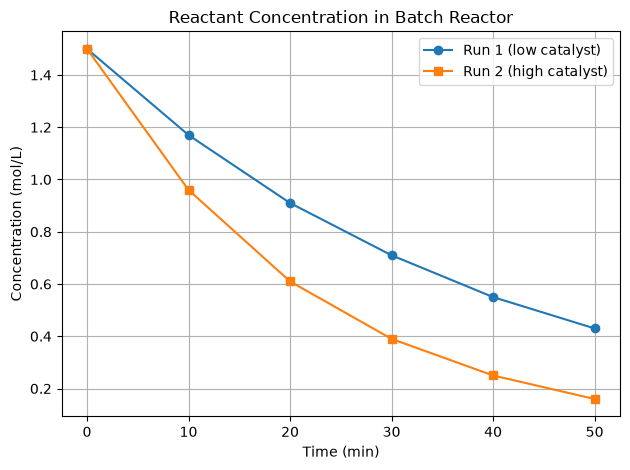

In [15]:
import matplotlib.pyplot as plt

plt.plot(kinetics_df["time_min"], kinetics_df["run1_mol_l"],
         marker="o", label="Run 1 (low catalyst)")
plt.plot(kinetics_df["time_min"], kinetics_df["run2_mol_l"],
         marker="s", label="Run 2 (high catalyst)")

plt.title("Reactant Concentration in Batch Reactor")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Mean value of p*V (k): 5.022 bar·L


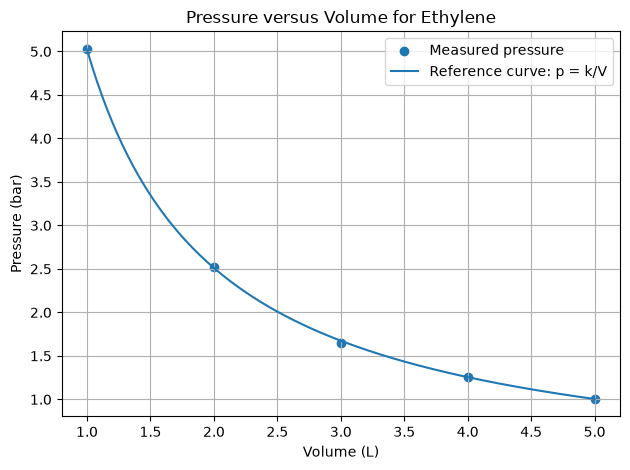

In [16]:
import numpy as np
import matplotlib.pyplot as plt

volume = np.array([1, 2, 3, 4, 5])
pressure_bar = np.array([5.03, 2.52, 1.65, 1.26, 1.01])

k = np.mean(volume * pressure_bar)
print(f"Mean value of p*V (k): {k:.3f} bar·L")

volume_curve = np.linspace(1, 5, 200)
pressure_curve = k / volume_curve

plt.scatter(volume, pressure_bar, label="Measured pressure")
plt.plot(volume_curve, pressure_curve, label="Reference curve: p = k/V")

plt.title("Pressure versus Volume for Ethylene")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()